# Atividade Spark SQL e Visualização

Considerando o dataset detalhado a seguir, extraia o conjunto de informações solicitadas.

### Dataset dados de COVID no Brasil

- Dados relativos a pacientes que realizaram exames de Covid19 no Brasil
- ~1.6GB
- 4.4M de instâncias

|  # | Nome do campo            | Descrição                                     |
| -: | ------------------------ | --------------------------------------------- |
|  0 | id                       | Identificador                                 |
|  1 | dataNotificacao          | Data da notificação                           |
|  2 | dataInicioSintomas       | Data do início dos sintomas                   |
|  3 | dataNascimento           | Data de nascimento                            |
|  4 | sintomas                 | Sintomas do paciente                          |
|  5 | profissionalSaude        | Relacionado a profissional de saúde           |
|  6 | cbo                      | Ocupação                                      |
|  7 | condicoes                | Condições do paciente                         |
|  8 | estadoTeste              | Estado do teste                               |
|  9 | dataTeste                | Data do teste                                 |
| 10 | tipoTeste                | Tipo de teste realizado                       |
| 11 | resultadoTeste           | Resultado do teste                            |
| 12 | paisOrigem               | País de origem do paciente                    |
| 13 | sexo                     | Sexo do paciente                              |
| 14 | bairro                   | Bairro do paciente                            |
| 15 | estado                   | Estado do paciente                            |
| 16 | estadoIBGE               | Estado do paciente — IBGE                     |
| 17 | municipio                | Município do paciente                         |
| 18 | municipioIBGE            | Município do paciente — IBGE                  |
| 19 | cep                      | CEP                                           |
| 20 | origem                   | Origem do paciente                            |
| 21 | cnes                     | Código da unidade de saúde                    |
| 22 | estadoNotificacao        | Estado da notificação                         |
| 23 | estadoNotificacaoIBGE    | Estado da notificação — IBGE                  |
| 24 | municipioNotificacao     | Município da notificação                      |
| 25 | municipioNotificacaoIBGE | Município da notificação — IBGE               |
| 26 | numeroNotificacao        | Número da notificação                         |
| 27 | excluido                 | ID de exclusão                                |
| 28 | validado                 | Local de validação                            |
| 29 | idade                    | Idade do paciente                             |
| 30 | dataEncerramento         | Data do encerramento da avaliação do paciente |
| 31 | evolucaoCaso             | Evolução do caso do paciente                  |
| 32 | classificacaoFinal       | Avaliação final do caso                       |


Informações a serem extraídas:

1. Gráfico exibindo os 10 sintomas mais comuns para casos positivos para corona virus
2. Gráfico da quantidade de pacientes com exames realizados ao longo do tempo
3. Gráfico da quantidade de pacientes positivos para corona virus (resultadoTeste) no PARANÁ vs SANTA CATARINA
4. Gráfico da quantidade de pacientes positivos para corona virus (resultadoTeste) em Curitiba vs São Paulo
5. Gráfico da quantidade de pacientes de Curitiba de acordo com o bairro
6. Gráfico comparando quantidade de pacientes positivos para corona virus (resultadoTeste) no PARANÁ e SANTA CATARINA ao longo dos dias
7. Gráfico comparando quantidade de pacientes que vieram a óbito (evolucaoCaso) no PARANÁ e SANTA CATARINA ao longo dos dias
8. Gráfico comparando os 10 sintomas mais comuns entre casos positivos e não positivos para corona virus
9. Gráfico comparando as idades das pessoas que realizaram exames no PARANÁ e em SANTA CATARINA
10. Gráfico comparando as idades das pessoas que realizaram exames no PARANÁ de acordo com o sexo
11. Gráfico comparando as idades das pessoas que realizaram exames no PARANÁ de acordo com a evolução do caso

In [1]:
#instala pyspark (execução local)
# O notebook é autossuficiente: instala as bibliotecas que faltarem, prepara um Java compatível
# com o Spark e, na célula de download, baixa a base para a mesma pasta do notebook.
import os, sys, glob, re, shutil, subprocess, importlib, importlib.util, importlib.metadata

def instala(*pacotes):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *pacotes])
    importlib.invalidate_caches()

# PySpark 3.5.9, a versão do enunciado. Ele roda com Python 3.9 a 3.12 (recomendado: 3.11);
# no Python 3.14 a serialização de funções do Spark 3.5 não funciona.
if sys.version_info >= (3, 14):
    raise RuntimeError('Use um kernel com Python 3.11 (o PySpark 3.5.9 não funciona no Python 3.14).')
PYSPARK_VERSAO = '3.5.9'
try:
    pyspark_instalado = importlib.metadata.version('pyspark')
except importlib.metadata.PackageNotFoundError:
    pyspark_instalado = None
if pyspark_instalado != PYSPARK_VERSAO:
    if 'pyspark' in sys.modules:
        raise RuntimeError('Outra versão do PySpark já foi carregada: reinicie o kernel e execute novamente a partir desta célula.')
    instala(f'pyspark=={PYSPARK_VERSAO}')

for modulo, pacote in [('gdown', 'gdown'), ('matplotlib', 'matplotlib'), ('pandas', 'pandas')]:
    if importlib.util.find_spec(modulo) is None:
        instala(pacote)

# O Spark 3.5 precisa de Java 8, 11, 17 ou 21. Se não houver um desses na máquina,
# um JDK 17 portátil é baixado uma única vez para ~/.jdk (não altera o sistema).
def versao_java(executavel):
    try:
        saida = subprocess.run([executavel, '-version'], capture_output=True, text=True).stderr
        maior, menor = re.search(r'version "(\d+)(?:\.(\d+))?', saida).groups()
        return int(menor) if maior == '1' else int(maior)
    except Exception:
        return None

def java_disponivel():
    if os.environ.get('JAVA_HOME'):
        exe = os.path.join(os.environ['JAVA_HOME'], 'bin', 'java')
        if shutil.which(exe) or os.path.exists(exe) or os.path.exists(exe + '.exe'):
            return exe
    return shutil.which('java')

if versao_java(java_disponivel()) not in (8, 11, 17, 21):
    if importlib.util.find_spec('jdk') is None:
        instala('install-jdk')
    import jdk
    pasta_jdk = os.path.join(os.path.expanduser('~'), '.jdk')
    instalados = sorted(glob.glob(os.path.join(pasta_jdk, 'jdk-17*')))
    java_home = instalados[-1] if instalados else jdk.install('17', path=pasta_jdk)
    if os.path.isdir(os.path.join(java_home, 'Contents', 'Home')):   # macOS
        java_home = os.path.join(java_home, 'Contents', 'Home')
    os.environ['JAVA_HOME'] = java_home
    os.environ['PATH'] = os.path.join(java_home, 'bin') + os.pathsep + os.environ['PATH']

# os processos Python do Spark usam o mesmo Python deste notebook (necessário no Windows)
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
print('Python', sys.version.split()[0], '| Java', versao_java(java_disponivel()))

Python 3.11.18 | Java 21


In [2]:
# abre sessão no spark sql
from pyspark.sql import SparkSession
import pyspark.sql.functions as func
import matplotlib.pyplot as plt

sc = SparkSession \
    .builder \
    .master('local[*]') \
    .config('spark.driver.memory', '4g') \
    .config('spark.driver.host', 'localhost') \
    .config('spark.sql.session.timeZone', 'UTC') \
    .config('spark.sql.ansi.enabled', 'false') \
    .config('spark.python.authenticate.socketTimeout', '1h') \
    .getOrCreate()
sc.sparkContext.setLogLevel('ERROR')
print('Spark', sc.version)

Spark 3.5.9


In [3]:
#Efetua download do arquivo covid
# baixa a base (cópia no Google Drive do aluno) para a pasta do notebook, se ainda não estiver lá
from pathlib import Path
import gdown

ARQUIVO = Path('covid.csv')
if not ARQUIVO.exists():
    gdown.download(id='1ysFQNX8db5B7WYIUq6yLxefr-kM_8HIp', output=str(ARQUIVO), quiet=False)
# file:///E:/pasta com espaços/arquivo.csv (sem codificar espaços e acentos, que o Hadoop não decodifica)
CAMINHO = 'file:///' + ARQUIVO.resolve().as_posix().lstrip('/')
print(ARQUIVO.name, f'{ARQUIVO.stat().st_size / 1e6:.0f} MB')

covid.csv 1637 MB


In [4]:
df = sc.read \
    .option('delimiter', ';') \
    .option('header', 'true') \
    .option('inferschema', 'true') \
    .csv(CAMINHO)

## Preparação dos dados

O princípio dos slides de Visualização guia toda a atividade: **o Spark sumariza, o driver só recebe o resumo e o Matplotlib desenha**. Nenhum gráfico é feito a partir dos 4,4 milhões de linhas; cada consulta termina em um `groupBy(...).agg(...)` cujo resultado (dezenas ou centenas de linhas) é trazido com `collect()` e convertido em listas para o `plt`.

Para cada informação há três células: a consulta no Spark, o gráfico e um comentário sobre o que o gráfico mostra.

In [5]:
df.printSchema()
print('Registros:', df.count())

root
 |-- id: string (nullable = true)
 |-- dataNotificacao: string (nullable = true)
 |-- dataInicioSintomas: string (nullable = true)
 |-- dataNascimento: timestamp (nullable = true)
 |-- sintomas: string (nullable = true)
 |-- profissionalSaude: string (nullable = true)
 |-- cbo: string (nullable = true)
 |-- condicoes: string (nullable = true)
 |-- estadoTeste: string (nullable = true)
 |-- dataTeste: timestamp (nullable = true)
 |-- tipoTeste: string (nullable = true)
 |-- resultadoTeste: string (nullable = true)
 |-- paisOrigem: string (nullable = true)
 |-- sexo: string (nullable = true)
 |-- bairro: string (nullable = true)
 |-- estado: string (nullable = true)
 |-- estadoIBGE: string (nullable = true)
 |-- municipio: string (nullable = true)
 |-- municipioIBGE: string (nullable = true)
 |-- cep: string (nullable = true)
 |-- origem: string (nullable = true)
 |-- cnes: string (nullable = true)
 |-- estadoNotificacao: string (nullable = true)
 |-- estadoNotificacaoIBGE: string (

Registros: 4424604


In [6]:
# colunas usadas, colunas derivadas e cache
covid = df.select('sintomas', 'dataTeste', 'dataEncerramento', 'resultadoTeste', 'sexo',
                  'bairro', 'estado', 'municipio', 'idade', 'evolucaoCaso')\
          .withColumn('data_teste', func.to_date('dataTeste'))\
          .withColumn('data_obito', func.coalesce(func.to_date('dataEncerramento'), func.to_date('dataTeste')))\
          .withColumn('positivo', func.col('resultadoTeste') == 'Positivo')\
          .withColumn('municipio_n', func.lower(func.trim('municipio')))\
          .cache()
print('Registros em cache:', covid.count())
covid.select(func.min('data_teste'), func.max('data_teste')).show()

Registros em cache: 4424604


+---------------+---------------+
|min(data_teste)|max(data_teste)|
+---------------+---------------+
|     2020-01-01|     2020-08-03|
+---------------+---------------+



In [7]:
plt.rcParams.update({'figure.figsize': (10, 4.8), 'figure.dpi': 110, 'axes.grid': True,
                     'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 10})
COR = {'PARANÁ': '#1f4e79', 'SANTA CATARINA': '#c55a11', 'positivo': '#7b2d26', 'nao': '#8c8c8c'}

def salvar(nome):
    # os gráficos ficam embutidos no próprio notebook (nenhum arquivo é gravado em disco)
    plt.tight_layout()
    plt.show()

import numpy as np
import pandas as pd

def media_movel(datas, valores, janela=7):
    """Completa os dias sem registro com zero e calcula a média móvel dos últimos `janela` dias."""
    s = pd.Series(valores, index=pd.to_datetime(datas))
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq='D'), fill_value=0)
    return s.index, s.rolling(janela, min_periods=1).mean().values

def rotulos_barras(ax, barras, fmt='{:,.0f}'):
    for b in barras:
        ax.annotate(fmt.format(b.get_height()).replace(',', '.'),
                    (b.get_x() + b.get_width() / 2, b.get_height()),
                    ha='center', va='bottom', fontsize=9)

In [8]:
# um sintoma por linha: 'Tosse, Febre' vira duas linhas; grafias diferentes são unificadas
CANON = {'dor de garganta': 'Dor de Garganta', 'dispneia': 'Dispneia', 'dispnéia': 'Dispneia',
         'dispineia': 'Dispneia', 'dificuldade de respirar': 'Dificuldade de Respirar',
         'tosse': 'Tosse', 'febre': 'Febre', 'outros': 'Outros',
         'outros: paciente assintomático': 'Assintomático', 'paciente assintomático': 'Assintomático', 'diarreia': 'Diarreia', 'diarréia': 'Diarreia'}
mapa = func.create_map([func.lit(x) for kv in CANON.items() for x in kv])

# alguns registros têm sintomas colados sem vírgula ('TosseDificuldade De Respirar'); a regex separa
colados = r'(?i)(tosse|febre|dispneia|outros|dor de garganta)(dificuldade|dor|febre|tosse|dispneia|outros)'
sintomas = covid.where(func.col('sintomas').isNotNull())\
                .withColumn('sintomas', func.regexp_replace('sintomas', colados, '$1, $2'))\
                .select('positivo', func.explode(func.split('sintomas', ',')).alias('s'))\
                .withColumn('s', func.trim('s'))\
                .where(~func.lower('s').isin('', 'null', 'undefined'))\
                .withColumn('sintoma', func.coalesce(mapa[func.lower('s')], func.col('s')))

**Definições adotadas:**

- **positivo**: `resultadoTeste == 'Positivo'`; **não positivo**: qualquer outro valor, inclusive resultado ausente;
- **data dos exames**: `dataTeste`; para óbitos, `dataEncerramento` (data do desfecho) e, na falta dela, `dataTeste`;
- **Paraná / Santa Catarina**: estado de residência (`estado`); **Curitiba / São Paulo**: município de residência, exigindo também o estado correspondente para descartar registros inconsistentes;
- **idade**: só valores entre 0 e 110 anos entram nos gráficos de idade (a base tem idades digitadas como 7176, por exemplo);
- **município e bairro** são comparados com grafia padronizada (maiúsculas/minúsculas e, no bairro, sem acentos), porque a base grava o mesmo nome de formas diferentes (`SÍTIO CERCADO` e `SITIO CERCADO`);
- **sintomas**: o campo é uma lista separada por vírgulas; grafias diferentes do mesmo sintoma são unificadas, sintomas colados sem vírgula são separados e os marcadores `null`/`undefined` são descartados;
- **séries diárias**: dias sem registro entram como zero e a curva suavizada é a média móvel dos 7 dias anteriores, que remove o efeito do fim de semana (menos exames no sábado e no domingo).

In [9]:
covid.groupBy('estado').agg(func.count('*').alias('pacientes'),
                            func.sum(func.col('positivo').cast('int')).alias('positivos'),
                            func.sum((func.col('evolucaoCaso') == 'Óbito').cast('int')).alias('obitos'))\
     .orderBy(func.col('pacientes').desc()).show()

+-----------------+---------+---------+------+
|           estado|pacientes|positivos|obitos|
+-----------------+---------+---------+------+
|        SÃO PAULO|  2083442|   587225|  2096|
|     MINAS GERAIS|   585110|   125581|  1028|
|            BAHIA|   559746|   169591|  3589|
|RIO GRANDE DO SUL|   440413|    82106|   243|
|   RIO DE JANEIRO|   418934|   165388|  1658|
|   SANTA CATARINA|   294990|    94136|   397|
|           PARANÁ|    41969|     6183|   122|
+-----------------+---------+---------+------+



In [10]:
#informacao 1 - Gráfico exibindo os 10 sintomas mais comuns para casos positivos para corona virus
top_sint_pos = sintomas.where(func.col('positivo'))\
                       .groupBy('sintoma').count()\
                       .orderBy(func.col('count').desc())\
                       .limit(10).collect()
qt_pos = covid.where(func.col('positivo')).count()
nomes = [r['sintoma'] for r in top_sint_pos]
qts = [r['count'] for r in top_sint_pos]
for n, q in zip(nomes, qts):
    print(f'{n:30s} {q:>9d}  {q / qt_pos:6.1%}')

Outros                            841588   68.4%
Tosse                             576207   46.8%
Febre                             462102   37.6%
Dor de Garganta                   290172   23.6%
Dispneia                          185676   15.1%
Assintomático                      24501    2.0%
Dificuldade de Respirar               63    0.0%
Diarreia                               6    0.0%
congestão nasal                        4    0.0%
perca de olfato e paladar              2    0.0%


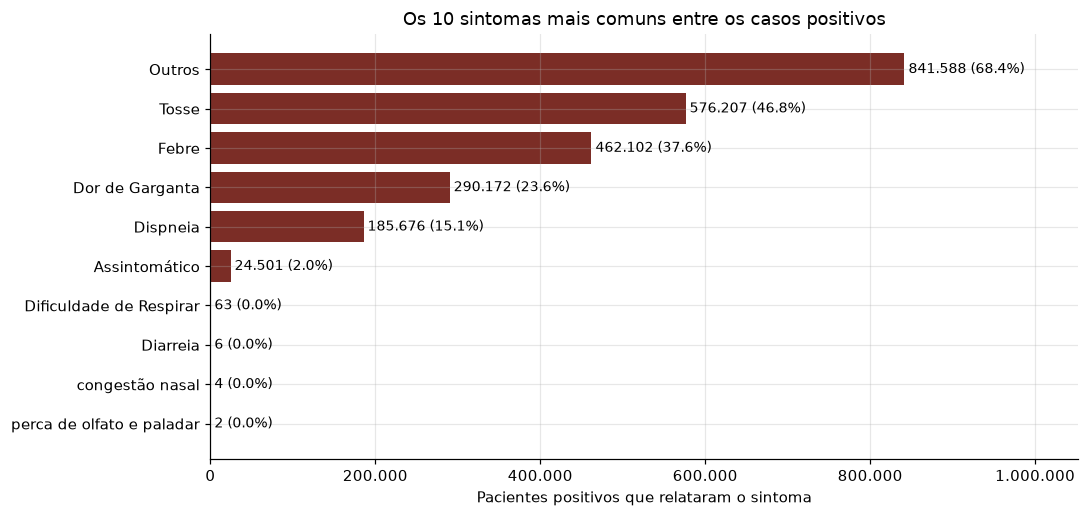

In [11]:
fig, ax = plt.subplots()
barras = ax.barh(nomes[::-1], qts[::-1], color=COR['positivo'])
for b, q in zip(barras, qts[::-1]):
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f' {q:,}'.replace(',', '.') + f' ({q / qt_pos:.1%})',
            va='center', fontsize=9)
ax.set_xlabel('Pacientes positivos que relataram o sintoma')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'.replace(',', '.')))
ax.set_title('Os 10 sintomas mais comuns entre os casos positivos')
ax.set_xlim(0, max(qts) * 1.25)
salvar('01_top10_sintomas_positivos')

**Resposta.** Entre os 1.230.210 positivos, os sintomas mais relatados são **Outros (68,4 %), Tosse (46,8 %), Febre (37,6 %), Dor de Garganta (23,6 %) e Dispneia (15,1 %)**, seguidos de Assintomático (2,0 %). A partir do 7º lugar as barras praticamente desaparecem: o campo `sintomas` tem seis categorias padronizadas e o restante é texto livre raro (Dificuldade de Respirar, Diarreia, congestão nasal...). O gráfico deixa isso evidente, o que uma tabela com dez linhas esconderia.

In [12]:
#informacao 2 - Gráfico da quantidade de pacientes com exames realizados ao longo do tempo
exames_dia = covid.where(func.col('data_teste') >= '2020-01-01')\
                  .groupBy('data_teste').count()\
                  .orderBy('data_teste').collect()
datas = [r['data_teste'] for r in exames_dia]
exames = [r['count'] for r in exames_dia]
print('Dias:', len(datas), '| de', datas[0], 'a', datas[-1])
pico = max(exames_dia, key=lambda r: r['count'])
print('Pico:', pico['data_teste'], 'com', pico['count'], 'pacientes')

Dias: 216 | de 2020-01-01 a 2020-08-03
Pico: 2020-07-13 com 99016 pacientes


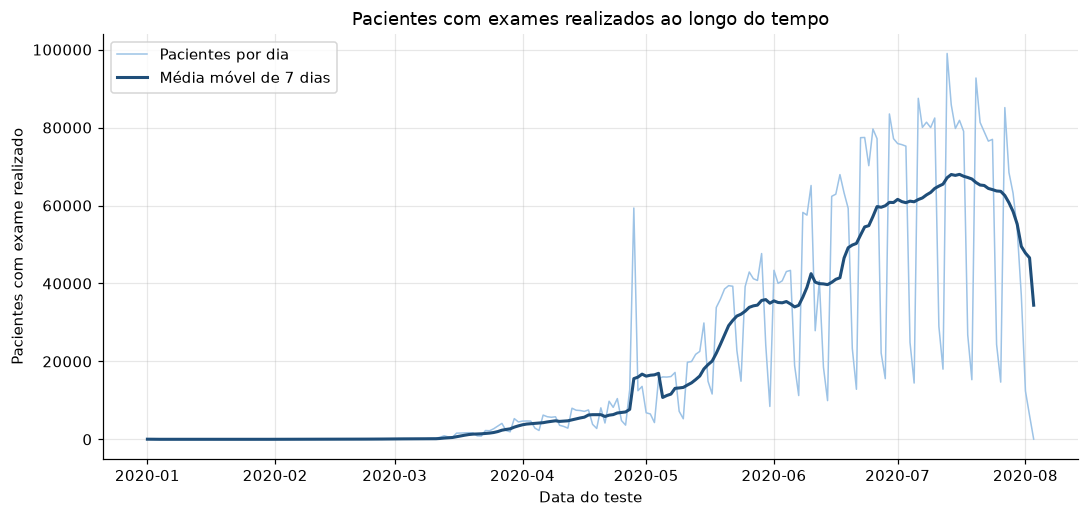

In [13]:
dias7, media7 = media_movel(datas, exames)

fig, ax = plt.subplots()
ax.plot(datas, exames, color='#9dc3e6', linewidth=1, label='Pacientes por dia')
ax.plot(dias7, media7, color='#1f4e79', linewidth=2, label='Média móvel de 7 dias')
ax.set_ylabel('Pacientes com exame realizado')
ax.set_xlabel('Data do teste')
ax.set_title('Pacientes com exames realizados ao longo do tempo')
ax.legend()
salvar('02_exames_ao_longo_do_tempo')

**Resposta.** Os exames começam em volume pequeno em março, crescem a partir de abril e chegam ao **pico em 13/07/2020, com 99.016 pacientes em um dia**. A curva diária é serrilhada porque há bem menos exames aos sábados e domingos; a média móvel de 7 dias remove esse efeito e mostra a tendência de alta até meados de julho. Dois pontos merecem cuidado: o salto isolado de **28/04/2020 (59.367 exames, quase cinco vezes os dias vizinhos)**, que tem cara de lançamento em lote no sistema, e a queda dos últimos dias, que reflete exames ainda não registrados.

In [14]:
#informacao 3 - Gráfico da quantidade de pacientes positivos para corona virus (resultadoTeste) no PARANÁ
pr_sc = covid.where(func.col('positivo') & func.col('estado').isin('PARANÁ', 'SANTA CATARINA'))\
             .groupBy('estado').count().orderBy('estado').collect()
for r in pr_sc:
    print(r['estado'], r['count'])

PARANÁ 6183
SANTA CATARINA 94136


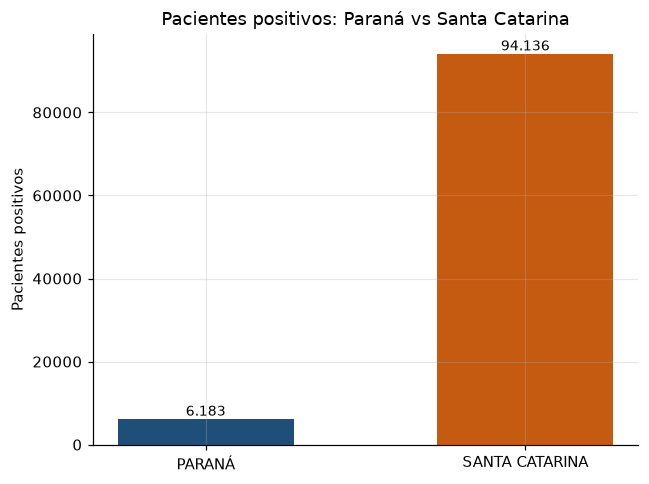

In [15]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ufs = [r['estado'] for r in pr_sc]
barras = ax.bar(ufs, [r['count'] for r in pr_sc], color=[COR[u] for u in ufs], width=0.55)
rotulos_barras(ax, barras)
ax.set_ylabel('Pacientes positivos')
ax.set_title('Pacientes positivos: Paraná vs Santa Catarina')
salvar('03_positivos_pr_vs_sc')

**Resposta.** **Santa Catarina tem 94.136 pacientes positivos e o Paraná, 6.183**, cerca de 15 vezes menos. Atenção: a diferença diz mais sobre a cobertura da base do que sobre a epidemia. O Paraná tem só 41.969 registros na base, contra 294.990 de Santa Catarina, embora tenha população maior, provavelmente porque o estado registrava boa parte dos casos em outro sistema. A proporção de positivos entre os testados (14,7 % no PR e 31,9 % em SC) é uma comparação mais justa.

In [16]:
#informacao 4 - Gráfico da quantidade de pacientes positivos para corona virus (resultadoTeste) em Curitiba
cwb_sp = covid.where(func.col('positivo') &
                     (((func.col('municipio_n') == 'curitiba') & (func.col('estado') == 'PARANÁ')) |
                      ((func.col('municipio_n') == 'são paulo') & (func.col('estado') == 'SÃO PAULO'))))\
              .groupBy('municipio_n').count().orderBy('municipio_n').collect()
for r in cwb_sp:
    print(r['municipio_n'], r['count'])

curitiba 2164
são paulo 210569


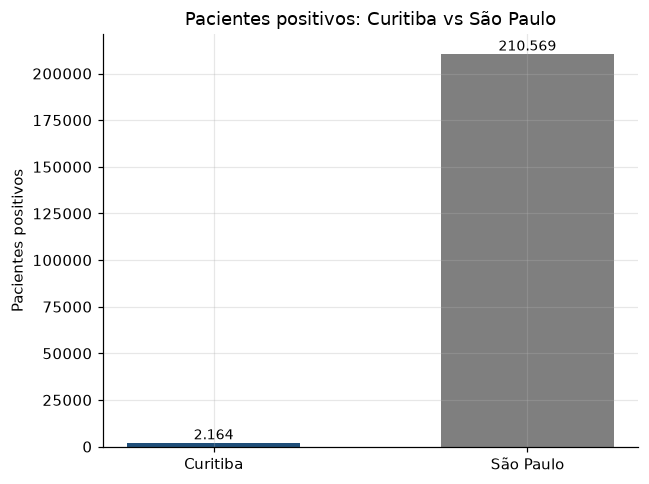

In [17]:
fig, ax = plt.subplots(figsize=(6, 4.5))
nomes_m = [r['municipio_n'].title() for r in cwb_sp]
barras = ax.bar(nomes_m, [r['count'] for r in cwb_sp], color=['#1f4e79', '#7f7f7f'], width=0.55)
rotulos_barras(ax, barras)
ax.set_ylabel('Pacientes positivos')
ax.set_title('Pacientes positivos: Curitiba vs São Paulo')
salvar('04_positivos_curitiba_vs_sao_paulo')

**Resposta.** **São Paulo tem 210.569 pacientes positivos e Curitiba, 2.164.** Também aqui a cobertura da base pesa: o estado de São Paulo concentra quase metade de todos os registros, enquanto Curitiba aparece com menos de 10 mil. O gráfico de barras com rótulos mostra a ordem de grandeza; para comparar as cidades de forma justa seria preciso dividir pelo número de testes ou pela população.

In [18]:
#informacao 5 - Gráfico da quantidade de pacientes de Curitiba de acordo com o bairro
cwb = covid.where((func.col('municipio_n') == 'curitiba') & (func.col('estado') == 'PARANÁ'))\
           .withColumn('bairro_n', func.translate(func.upper(func.trim('bairro')),
                                                  'ÁÀÂÃÉÊÍÓÔÕÚÜÇ', 'AAAAEEIOOOUUC'))
total_cwb = cwb.count()
sem_bairro = cwb.where(func.col('bairro_n').isNull() | func.col('bairro_n').isin('', 'NULL', 'UNDEFINED')).count()
bairros = cwb.where(func.col('bairro_n').isNotNull() & ~func.col('bairro_n').isin('', 'NULL', 'UNDEFINED'))\
             .groupBy('bairro_n').count()\
             .orderBy(func.col('count').desc())
print('Pacientes de Curitiba:', total_cwb, '| sem bairro informado:', sem_bairro)
print('Bairros distintos (grafia padronizada):', bairros.count())
top_bairros = bairros.limit(25).collect()
for r in top_bairros[:10]:
    print(f"{r['bairro_n']:25s} {r['count']}")

Pacientes de Curitiba: 9877 | sem bairro informado: 821


Bairros distintos (grafia padronizada): 415


CIDADE INDUSTRIAL         639
SITIO CERCADO             633
UBERABA                   368
AGUA VERDE                345
CAJURU                    343
CENTRO                    335
BOQUEIRAO                 290
XAXIM                     264
PORTAO                    253
NOVO MUNDO                237


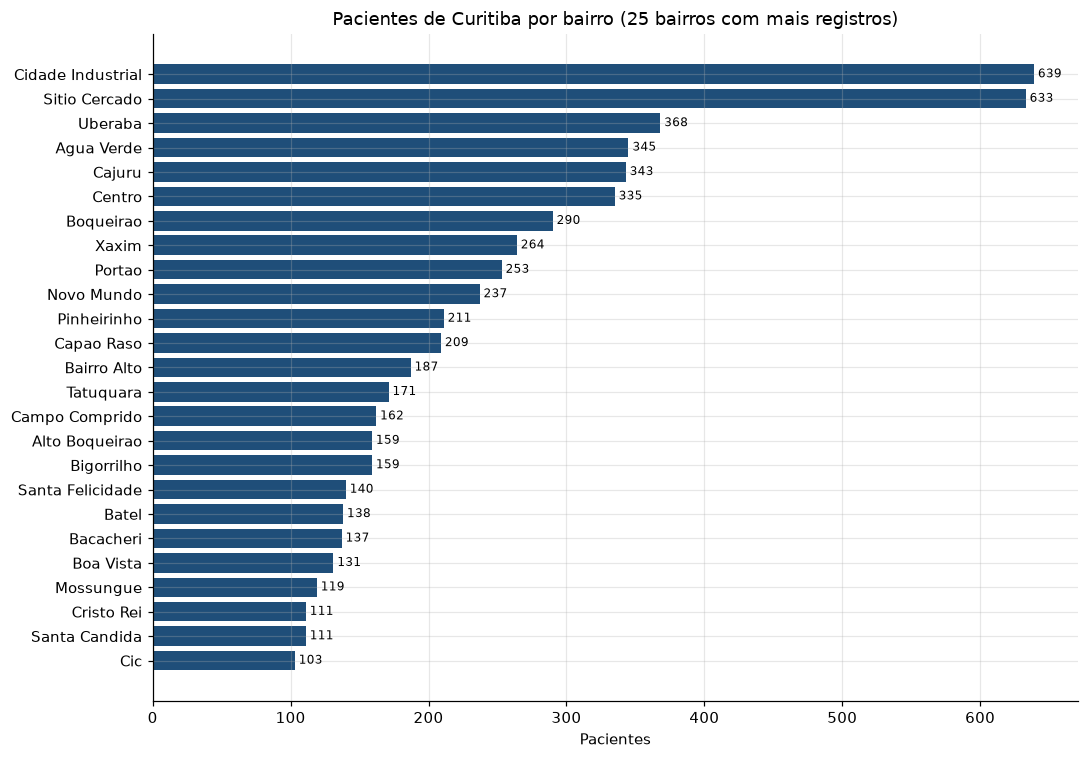

In [19]:
fig, ax = plt.subplots(figsize=(10, 7))
nb_ = [r['bairro_n'].title() for r in top_bairros][::-1]
qb = [r['count'] for r in top_bairros][::-1]
barras = ax.barh(nb_, qb, color='#1f4e79')
for b, q in zip(barras, qb):
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f' {q}', va='center', fontsize=8)
ax.set_xlabel('Pacientes')
ax.set_title('Pacientes de Curitiba por bairro (25 bairros com mais registros)')
salvar('05_curitiba_por_bairro')

**Resposta.** Curitiba tem 9.877 pacientes na base, distribuídos por **415 bairros** (após padronizar maiúsculas e acentos; 821 registros não informam o bairro). Os bairros com mais pacientes são **Cidade Industrial (639) e Sítio Cercado (633)**, seguidos de Uberaba (368), Água Verde (345), Cajuru (343) e Centro (335). Os primeiros são justamente os bairros mais populosos da cidade. O 25º item, "Cic", é a sigla da própria Cidade Industrial de Curitiba, um exemplo de que a padronização de texto livre nunca é completa.

In [20]:
#informacao 6 - Gráfico comparando quantidade de pacientes positivos para corona virus (resultadoTeste) no PARANÁ e SANTA CATARINA ao longo dos dias
pos_dia_uf = covid.where(func.col('positivo') & func.col('estado').isin('PARANÁ', 'SANTA CATARINA') &
                         (func.col('data_teste') >= '2020-01-01'))\
                  .groupBy('estado', 'data_teste').count()\
                  .orderBy('data_teste').collect()
serie = {uf: ([r['data_teste'] for r in pos_dia_uf if r['estado'] == uf],
              [r['count'] for r in pos_dia_uf if r['estado'] == uf]) for uf in ['PARANÁ', 'SANTA CATARINA']}
for uf, (d, q) in serie.items():
    i = q.index(max(q))
    print(f'{uf}: {sum(q)} positivos em {len(d)} dias; pico em {d[i]} com {q[i]}')

PARANÁ: 6183 positivos em 148 dias; pico em 2020-07-03 com 234
SANTA CATARINA: 94136 positivos em 170 dias; pico em 2020-07-20 com 3409


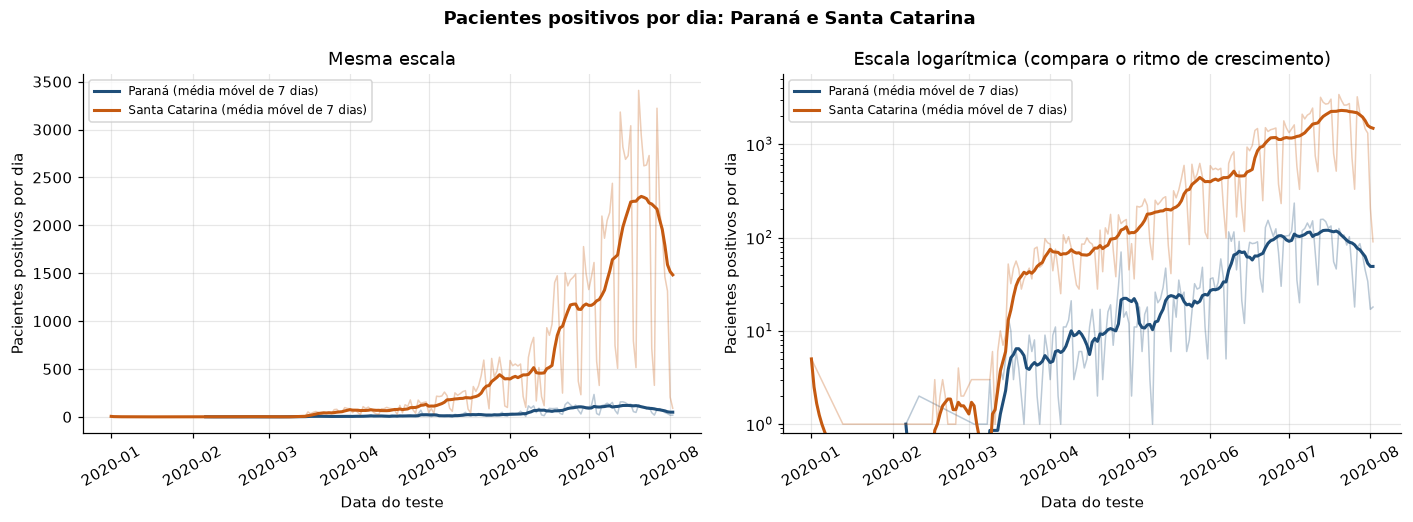

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for uf, (d, q) in serie.items():
    d7, m7 = media_movel(d, q)
    for ax in (ax1, ax2):
        ax.plot(d, q, color=COR[uf], alpha=0.3, linewidth=1)
        ax.plot(d7, m7, color=COR[uf], linewidth=2, label=f'{uf.title()} (média móvel de 7 dias)')
ax1.set_title('Mesma escala')
ax2.set_yscale('log')
ax2.set_ylim(bottom=0.8)
ax2.set_title('Escala logarítmica (compara o ritmo de crescimento)')
for ax in (ax1, ax2):
    ax.set_ylabel('Pacientes positivos por dia')
    ax.set_xlabel('Data do teste')
    ax.legend(fontsize=8)
    ax.tick_params(axis='x', rotation=30)
fig.suptitle('Pacientes positivos por dia: Paraná e Santa Catarina', fontweight='bold')
salvar('06_positivos_dia_pr_sc')

**Resposta.** Os dois estados seguem a mesma tendência de alta de março a julho, mas em escalas muito diferentes. Na mesma escala a curva do Paraná quase some; na escala logarítmica fica claro que **as duas crescem em ritmo parecido** (curvas quase paralelas), com Santa Catarina sempre cerca de uma ordem de grandeza acima. **Picos diários: Santa Catarina em 20/07/2020 (3.409 positivos) e Paraná em 03/07/2020 (234).** A queda no fim da série é o atraso de registro já visto na informação 2.

In [22]:
#informacao 7 - Gráfico comparando quantidade de pacientes que vieram a óbito (evolucaoCaso) no PARANÁ e SANTA CATARINA ao longo dos dias
obitos_dia_uf = covid.where((func.col('evolucaoCaso') == 'Óbito') &
                            func.col('estado').isin('PARANÁ', 'SANTA CATARINA') &
                            (func.col('data_obito') >= '2020-01-01'))\
                     .groupBy('estado', 'data_obito').count()\
                     .orderBy('data_obito').collect()
serie_ob = {uf: ([r['data_obito'] for r in obitos_dia_uf if r['estado'] == uf],
                 [r['count'] for r in obitos_dia_uf if r['estado'] == uf]) for uf in ['PARANÁ', 'SANTA CATARINA']}
for uf, (d, q) in serie_ob.items():
    print(f'{uf}: {sum(q)} óbitos em {len(d)} dias com registro; máximo diário {max(q)}')

PARANÁ: 122 óbitos em 36 dias com registro; máximo diário 34
SANTA CATARINA: 397 óbitos em 117 dias com registro; máximo diário 14


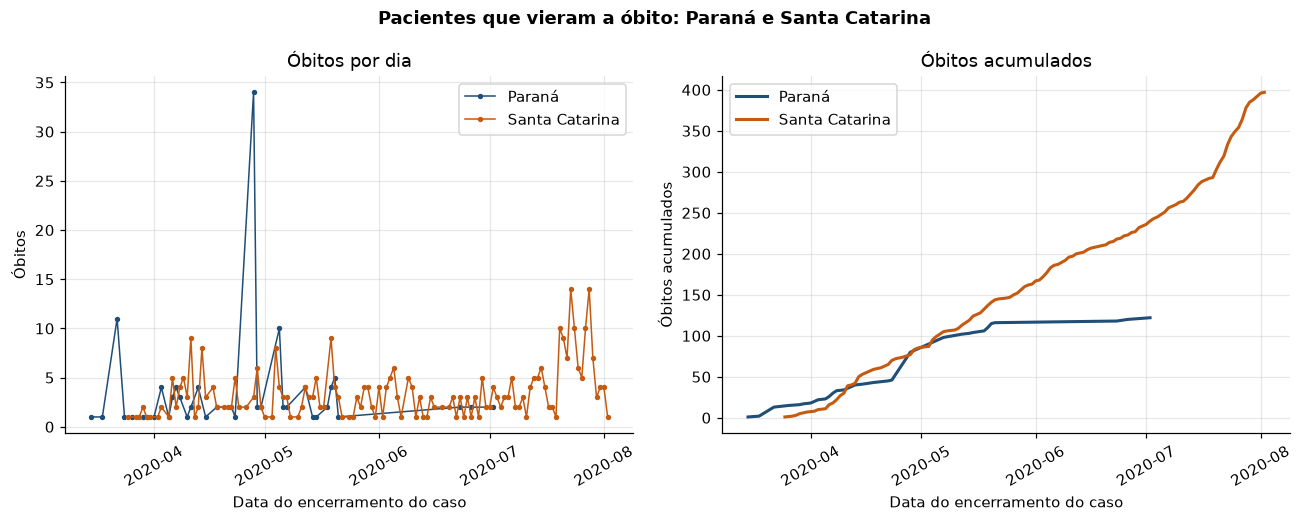

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
for uf, (d, q) in serie_ob.items():
    ax1.plot(d, q, color=COR[uf], marker='o', markersize=2.5, linewidth=1, label=uf.title())
    ax2.plot(d, np.cumsum(q), color=COR[uf], linewidth=2, label=uf.title())
ax1.set_title('Óbitos por dia')
ax1.set_ylabel('Óbitos')
ax2.set_title('Óbitos acumulados')
ax2.set_ylabel('Óbitos acumulados')
for a in (ax1, ax2):
    a.set_xlabel('Data do encerramento do caso')
    a.legend()
    a.tick_params(axis='x', rotation=30)
fig.suptitle('Pacientes que vieram a óbito: Paraná e Santa Catarina', fontweight='bold')
salvar('07_obitos_dia_pr_sc')

**Resposta.** Santa Catarina tem **397 óbitos** distribuídos em 117 dias, com uma curva acumulada que acelera a partir de julho. O Paraná tem **122 óbitos** em apenas 36 dias com registro, e **34 deles têm a mesma data de encerramento, 28/04/2020**: é a mesma data do salto de exames da informação 2, o que indica fechamento de casos em lote, e não 34 mortes em um dia. A curva acumulada do Paraná praticamente para depois de maio, o que reforça que os registros do estado nessa base são incompletos. Como óbitos são poucos por dia, o gráfico acumulado (à direita) é mais legível que o diário.

In [24]:
#informacao 8 - Gráfico comparando os 10 sintomas mais comuns entre casos positivos e não positivos para corona virus
qt_grupo = {r['positivo']: r['count'] for r in covid.groupBy('positivo').count().collect()}
qt_pos_g = qt_grupo.get(True, 0)
qt_nao_g = sum(v for k, v in qt_grupo.items() if k is not True)   # False e resultado ausente

por_grupo = sintomas.withColumn('grupo', func.when(func.col('positivo'), 'positivo').otherwise('nao'))\
                    .groupBy('sintoma', 'grupo').count().collect()
cont = {}
for r in por_grupo:
    cont.setdefault(r['sintoma'], {'positivo': 0, 'nao': 0})[r['grupo']] = r['count']

# os 10 sintomas mais frequentes no total, comparados como % de cada grupo
top10_total = sorted(cont, key=lambda s: -(cont[s]['positivo'] + cont[s]['nao']))[:10]
pct_pos = [cont[s]['positivo'] / qt_pos_g * 100 for s in top10_total]
pct_nao = [cont[s]['nao'] / qt_nao_g * 100 for s in top10_total]
print(f'positivos: {qt_pos_g} | não positivos: {qt_nao_g}')
for s, a, b in zip(top10_total, pct_pos, pct_nao):
    print(f'{s:30s} positivos {a:6.2f}%   não positivos {b:6.2f}%   razão {a / b if b else float("nan"):5.2f}')

positivos: 1230210 | não positivos: 3194394
Outros                         positivos  68.41%   não positivos  65.42%   razão  1.05
Tosse                          positivos  46.84%   não positivos  35.29%   razão  1.33
Febre                          positivos  37.56%   não positivos  23.59%   razão  1.59
Dor de Garganta                positivos  23.59%   não positivos  22.82%   razão  1.03
Dispneia                       positivos  15.09%   não positivos  12.70%   razão  1.19
Assintomático                  positivos   1.99%   não positivos   8.17%   razão  0.24
Dificuldade de Respirar        positivos   0.01%   não positivos   0.17%   razão  0.03
Diarreia                       positivos   0.00%   não positivos   0.00%   razão  1.20
congestão nasal                positivos   0.00%   não positivos   0.00%   razão  3.46
calafrio                       positivos   0.00%   não positivos   0.00%   razão  1.73


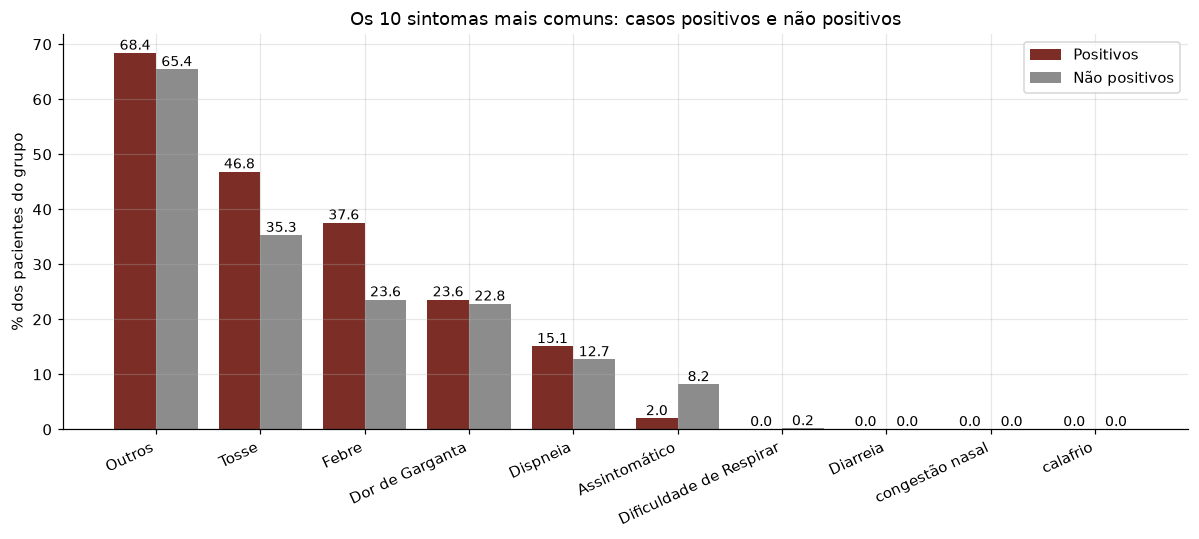

In [25]:
x = np.arange(len(top10_total))
fig, ax = plt.subplots(figsize=(11, 5))
b1 = ax.bar(x - 0.2, pct_pos, 0.4, color=COR['positivo'], label='Positivos')
b2 = ax.bar(x + 0.2, pct_nao, 0.4, color=COR['nao'], label='Não positivos')
rotulos_barras(ax, b1, '{:.1f}')
rotulos_barras(ax, b2, '{:.1f}')
ax.set_xticks(x)
ax.set_xticklabels(top10_total, rotation=25, ha='right')
ax.set_ylabel('% dos pacientes do grupo')
ax.set_title('Os 10 sintomas mais comuns: casos positivos e não positivos')
ax.legend()
salvar('08_sintomas_positivos_vs_nao_positivos')

**Resposta.** Como os grupos têm tamanhos muito diferentes (1,23 milhão de positivos e 3,19 milhões de não positivos), a comparação é feita em **% de cada grupo**. A ordem dos sintomas é a mesma, mas **febre (37,6 % contra 23,6 %) e tosse (46,8 % contra 35,3 %) são bem mais frequentes entre os positivos**, e dispneia um pouco mais (15,1 % contra 12,7 %). Dor de garganta e "Outros" quase não discriminam. "Assintomático" vai no sentido oposto: 8,2 % dos não positivos contra 2,0 % dos positivos, o que faz sentido, porque pessoas sem sintomas testadas por rastreamento tendem a dar negativo.

In [26]:
#informacao 9 - Gráfico comparando as idades das pessoas que realizaram exames no PARANÁ e em SANTA CATARINA
def resumo_idade(dados, grupo, ordem, largura=5):
    """Distribuição por faixa etária e quartis por grupo, calculados no Spark."""
    base = dados.where(func.col('idade').between(0, 110))
    faixas = base.withColumn('faixa', (func.floor(func.col('idade') / largura) * largura).cast('int'))\
                 .groupBy(grupo, 'faixa').count().collect()
    quartis = base.groupBy(grupo).agg(
        func.count('*').alias('n'),
        func.mean('idade').alias('media'),
        func.percentile_approx('idade', [0.05, 0.25, 0.5, 0.75, 0.95], 10000).alias('q')).collect()
    q = {r[grupo]: r for r in quartis}
    dist = {}
    for g in ordem:
        tot = q[g]['n']
        cont_f = {r['faixa']: r['count'] for r in faixas if r[grupo] == g}
        dist[g] = [cont_f.get(f, 0) / tot * 100 for f in range(0, 111, largura)]
    return dist, q, largura

def grafico_idade(resumo, ordem, cores, rotulos, titulo, arquivo):
    dist, q, largura = resumo
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1.6, 1]})
    faixas = list(range(0, 111, largura))
    for g in ordem:
        ax1.plot(faixas, dist[g], marker='o', markersize=3, color=cores[g], label=f'{rotulos[g]} (n={q[g]["n"]:,})'.replace(',', '.'))
    ax1.set_xlabel(f'Idade (início da faixa de {largura} anos)')
    ax1.set_ylabel('% dos pacientes do grupo')
    ax1.set_title('Distribuição das idades')
    ax1.legend(fontsize=8)
    caixas = [{'label': rotulos[g], 'whislo': q[g]['q'][0], 'q1': q[g]['q'][1], 'med': q[g]['q'][2],
               'q3': q[g]['q'][3], 'whishi': q[g]['q'][4], 'mean': q[g]['media'], 'fliers': []} for g in ordem]
    bp = ax2.bxp(caixas, showmeans=True, patch_artist=True)
    for patch, g in zip(bp['boxes'], ordem):
        patch.set_facecolor(cores[g]); patch.set_alpha(0.55)
    ax2.set_ylabel('Idade (anos)')
    ax2.set_title('Quartis (bigodes: percentis 5 e 95; triângulo: média)')
    plt.setp(ax2.get_xticklabels(), rotation=30, ha='right')
    fig.suptitle(titulo, fontweight='bold')
    salvar(arquivo)

def imprime_quartis(q, ordem):
    for g in ordem:
        p5, p25, p50, p75, p95 = q[g]['q']
        print(f'{str(g):26s} n={q[g]["n"]:>7d}  média={q[g]["media"]:5.1f}  P5={p5} Q1={p25} mediana={p50} Q3={p75} P95={p95}')

ordem_uf = ['PARANÁ', 'SANTA CATARINA']
res_uf = resumo_idade(covid.where(func.col('estado').isin(ordem_uf)), 'estado', ordem_uf)
imprime_quartis(res_uf[1], ordem_uf)

PARANÁ                     n=  41959  média= 39.0  P5=19 Q1=29 mediana=38 Q3=48 P95=67
SANTA CATARINA             n= 294974  média= 38.8  P5=17 Q1=28 mediana=37 Q3=49 P95=68


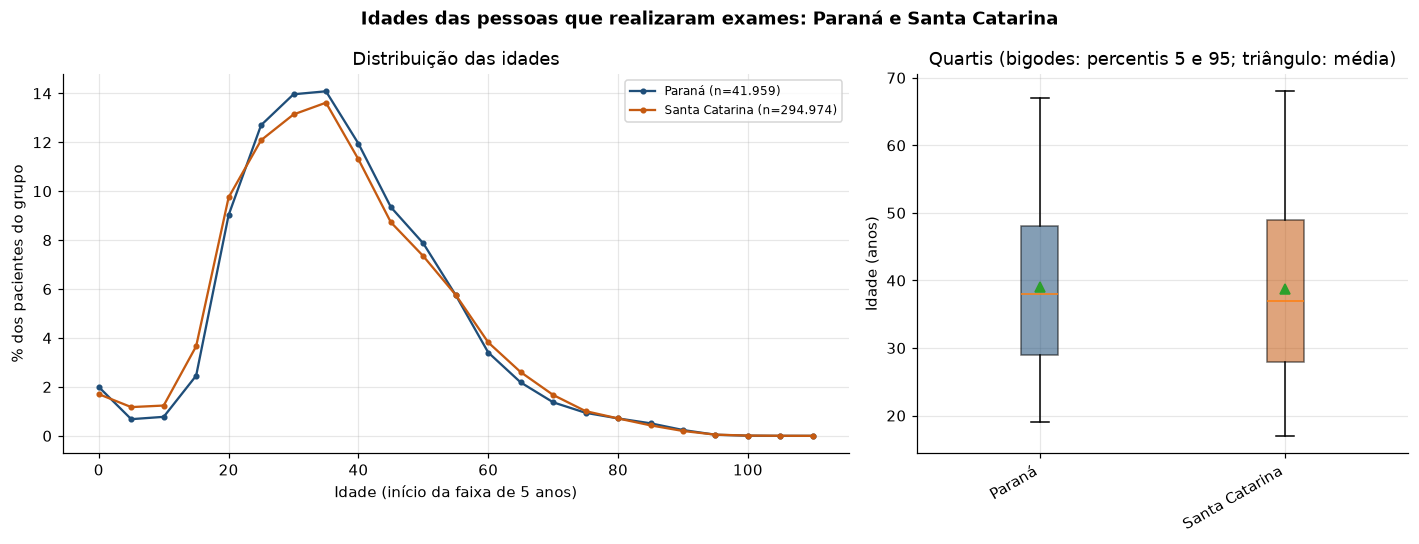

In [27]:
grafico_idade(res_uf, ordem_uf, COR, {u: u.title() for u in ordem_uf},
              'Idades das pessoas que realizaram exames: Paraná e Santa Catarina', '09_idades_pr_sc')

**Resposta.** As distribuições de idade dos dois estados são **quase idênticas**: concentração entre 20 e 50 anos (idade de quem trabalha e é testado), média de 39,0 anos no Paraná e 38,8 em Santa Catarina, mediana de 38 e 37 anos e quartis de 29 a 48 (PR) e 28 a 49 (SC). Santa Catarina tem uma fração um pouco maior de adolescentes (15 a 19 anos). As idades foram limitadas a 0 a 110 anos para descartar erros de digitação.

In [28]:
#informacao 10 - Gráfico comparando as idades das pessoas que realizaram exames no PARANÁ de acordo com o sexo
pr = covid.where(func.col('estado') == 'PARANÁ')
pr.groupBy('sexo').count().show()
ordem_sexo = ['Feminino', 'Masculino', 'Indefinido']
res_sexo = resumo_idade(pr.where(func.col('sexo').isin(ordem_sexo)), 'sexo', ordem_sexo)
imprime_quartis(res_sexo[1], ordem_sexo)

+----------+-----+
|      sexo|count|
+----------+-----+
|  Feminino|16250|
| Masculino|23743|
|Indefinido| 1783|
|      null|  193|
+----------+-----+



Feminino                   n=  16245  média= 38.6  P5=18 Q1=28 mediana=37 Q3=48 P95=68
Masculino                  n=  23738  média= 39.7  P5=19 Q1=29 mediana=38 Q3=49 P95=66
Indefinido                 n=   1783  média= 37.5  P5=21 Q1=29 mediana=36 Q3=45 P95=58


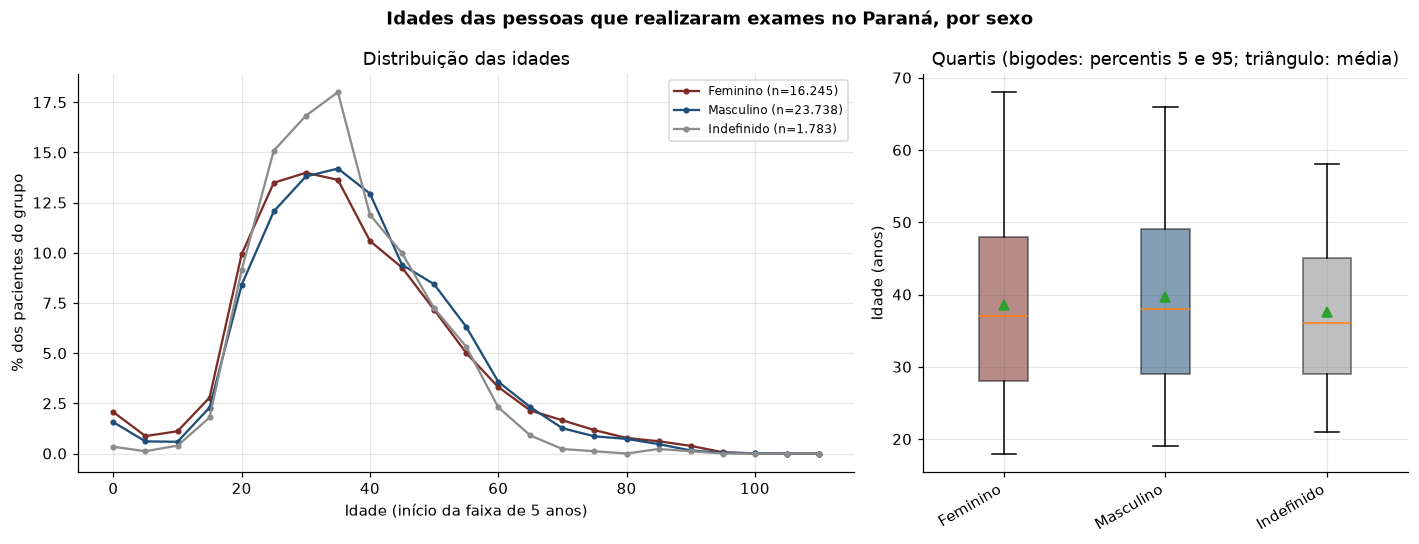

In [29]:
grafico_idade(res_sexo, ordem_sexo,
              {'Feminino': '#7b2d26', 'Masculino': '#1f4e79', 'Indefinido': '#8c8c8c'},
              {s: s for s in ordem_sexo},
              'Idades das pessoas que realizaram exames no Paraná, por sexo', '10_idades_pr_sexo')

**Resposta.** No Paraná, homens e mulheres testados têm perfis de idade muito próximos (médias de 39,7 e 38,6 anos; medianas de 38 e 37). Há **mais homens que mulheres testados no Paraná (23.743 contra 16.250)**, o contrário do padrão nacional da base. O grupo "Indefinido" (1.783 pessoas) é mais concentrado entre 25 e 45 anos e tem cauda menor de idosos.

In [30]:
#informacao 11 - Gráfico comparando as idades das pessoas que realizaram exames no PARANÁ de acordo com a evolução do caso
pr_evol = pr.withColumn('evolucao', func.coalesce(func.col('evolucaoCaso'), func.lit('Sem informação')))
pr_evol.groupBy('evolucao').count().orderBy(func.col('count').desc()).show(truncate=False)
ordem_evol = ['Sem informação', 'Cura', 'Em tratamento domiciliar', 'Ignorado', 'Cancelado',
              'Internado', 'Internado em UTI', 'Óbito']
presentes = {r['evolucao'] for r in pr_evol.select('evolucao').distinct().collect()}
ordem_evol = [e for e in ordem_evol if e in presentes]
# faixas de 10 anos: alguns grupos são pequenos (Internado em UTI tem 6 pacientes)
res_ev = resumo_idade(pr_evol, 'evolucao', ordem_evol, largura=10)
imprime_quartis(res_ev[1], ordem_evol)

+------------------------+-----+
|evolucao                |count|
+------------------------+-----+
|Sem informação          |38901|
|Cura                    |1835 |
|Cancelado               |595  |
|Ignorado                |346  |
|Em tratamento domiciliar|139  |
|Óbito                   |122  |
|Internado               |25   |
|Internado em UTI        |6    |
+------------------------+-----+



Sem informação             n=  38891  média= 38.9  P5=19 Q1=28 mediana=37 Q3=48 P95=66
Cura                       n=   1835  média= 39.6  P5=16 Q1=28 mediana=38 Q3=50 P95=71
Em tratamento domiciliar   n=    139  média= 39.5  P5=15 Q1=27 mediana=37 Q3=49 P95=77
Ignorado                   n=    346  média= 39.5  P5=18 Q1=29 mediana=36 Q3=50 P95=70
Cancelado                  n=    595  média= 39.3  P5=19 Q1=29 mediana=38 Q3=47 P95=68
Internado                  n=     25  média= 60.5  P5=40 Q1=56 mediana=59 Q3=65 P95=86
Internado em UTI           n=      6  média= 52.5  P5=30 Q1=46 mediana=48 Q3=70 P95=73
Óbito                      n=    122  média= 54.1  P5=20 Q1=38 mediana=56 Q3=70 P95=85


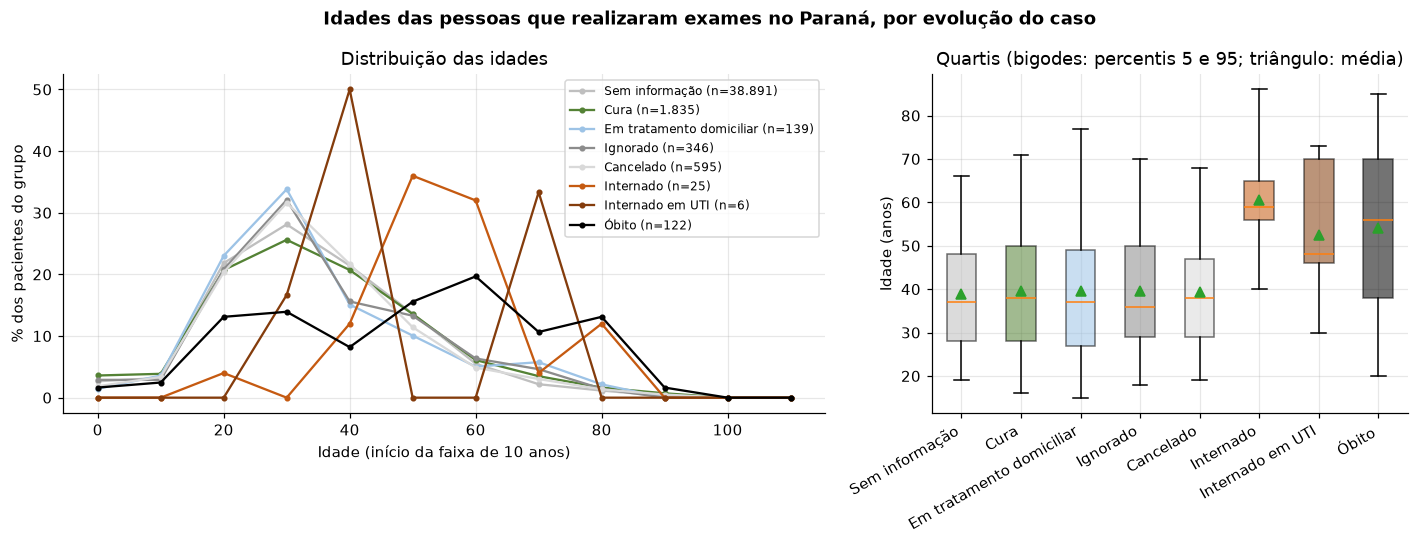

In [31]:
cores_ev = dict(zip(ordem_evol, ['#bfbfbf', '#548235', '#9dc3e6', '#8c8c8c', '#d9d9d9',
                                 '#c55a11', '#843c0c', '#000000'][:len(ordem_evol)]))
grafico_idade(res_ev, ordem_evol, cores_ev, {e: e for e in ordem_evol},
              'Idades das pessoas que realizaram exames no Paraná, por evolução do caso', '11_idades_pr_evolucao')

**Resposta.** Este é o gráfico em que a idade mais discrimina. Os desfechos leves ou sem informação (sem informação, cura, tratamento domiciliar, ignorado, cancelado) têm mediana entre 36 e 38 anos. Já **internados (mediana de 59 anos) e óbitos (mediana de 56, média de 54 anos, 25 % acima de 70)** são claramente mais velhos, o que concorda com a taxa de óbito crescente com a idade vista na Atividade 1. Os grupos "Internado" (25 pessoas) e "Internado em UTI" (6) são pequenos demais para conclusões firmes, por isso o $n$ aparece na legenda e as faixas são de 10 anos.